In [168]:
# import  livraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB,GaussianNB
from sklearn.metrics import classification_report,ConfusionMatrixDisplay,f1_score,precision_score,recall_score,accuracy_score

In [169]:
# load dataset
data=pd.read_csv("netflix_customer_churn.csv")

In [170]:
data

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,44f3ba44-b95d-4e50-a786-bac4d06f4a43,19,Female,Basic,49.17,11,Europe,Desktop,8.99,0,Credit Card,4,4.10,Drama
4996,18779bcb-ba2b-41da-b751-e70b812061ec,67,Female,Basic,9.24,2,North America,Desktop,8.99,0,PayPal,3,3.08,Documentary
4997,3f32e8c5-615b-4a3b-a864-db2688f7834f,66,Male,Standard,16.55,49,South America,Desktop,13.99,1,Debit Card,2,0.33,Action
4998,7b0ad82d-6571-430e-90f4-906259e0e89c,59,Female,Basic,9.12,3,Europe,Laptop,8.99,0,Credit Card,4,2.28,Sci-Fi


In [171]:
# dataset shape
data.shape

(5000, 14)

In [172]:
# columns info
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   str    
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   str    
 3   subscription_type       5000 non-null   str    
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   str    
 7   device                  5000 non-null   str    
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   str    
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   str    
dtypes: float64(3), int64(4), str(7)
memory usage: 920.1

In [173]:
# investigate duplicated values
data.duplicated().sum()

np.int64(0)

In [174]:
# investigate data inconsistence
for col in (data.select_dtypes(include="str").columns).drop("customer_id"):
    print(data[col].value_counts())
    print()

gender
Female    1711
Male      1654
Other     1635
Name: count, dtype: int64

subscription_type
Premium     1693
Basic       1661
Standard    1646
Name: count, dtype: int64

region
South America    873
Europe           867
North America    851
Asia             841
Africa           803
Oceania          765
Name: count, dtype: int64

device
Tablet     1048
Laptop     1006
Mobile     1004
TV          993
Desktop     949
Name: count, dtype: int64

payment_method
Debit Card     1030
PayPal         1026
Crypto          995
Gift Card       976
Credit Card     973
Name: count, dtype: int64

favorite_genre
Drama          731
Documentary    729
Romance        725
Sci-Fi         720
Horror         713
Action         697
Comedy         685
Name: count, dtype: int64



In [175]:
print(data.select_dtypes(include="number").columns)

Index(['age', 'watch_hours', 'last_login_days', 'monthly_fee', 'churned',
       'number_of_profiles', 'avg_watch_time_per_day'],
      dtype='str')


In [176]:
# investigate impossible data
for col in data.select_dtypes(include="number").columns:
    if col=="churned":
        for val in data[col]:
            if val!=1 and val!=0:
                print(val)
    elif col=="age":
        a=data[col]<18
        if a.sum()>0:
            print(data.loc[a,col])
    else:
        a=data[col]<0
        if a.sum()>0:
            print(data.loc[a,col])

In [177]:
# investigate null values
data.isnull().sum()

customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64

In [178]:
# copy original data
df=data.copy()

In [179]:
# drop customer id column
df=df.drop(columns="customer_id")

In [180]:
# Investigate outliers
for col in df.select_dtypes(include="number").columns:
    print(col)
    q1=df[col].quantile(0.25)
    q2=df[col].quantile(0.75)
    iqr=(q2-q1)
    lower_q=q1-(1.5*iqr)
    upper_q=q2+(1.5*iqr)
    # lower outliers
    print(f"""lower_q: {lower_q}
upper_q: {upper_q}""")
    a=df[col]<lower_q
    b=df[col]>upper_q
    if a.sum()>0:
        print("lower outliers")
        display(df.loc[a,col])
    elif b.sum()>0:
        display("upper outliers")
        display(df.loc[b,col])
    print()
    

age
lower_q: -12.0
upper_q: 100.0

watch_hours
lower_q: -15.70125
upper_q: 35.06875


'upper outliers'

15      40.94
22      43.02
44      46.88
49      49.49
57      48.35
        ...  
4962    70.99
4968    48.84
4979    71.38
4989    42.72
4995    49.17
Name: watch_hours, Length: 238, dtype: float64


last_login_days
lower_q: -30.0
upper_q: 90.0

monthly_fee
lower_q: -4.509999999999996
upper_q: 31.489999999999995

churned
lower_q: -1.5
upper_q: 2.5

number_of_profiles
lower_q: -1.0
upper_q: 7.0

avg_watch_time_per_day
lower_q: -0.805
upper_q: 1.635


'upper outliers'

15      5.12
20      6.38
23      1.73
39      2.17
52      2.14
        ... 
4971    3.12
4979    2.16
4995    4.10
4996    3.08
4998    2.28
Name: avg_watch_time_per_day, Length: 549, dtype: float64

ANALYSIS

In [181]:
# Descriptive statistics for numerical columns
df.describe()

,age,watch_hours,last_login_days,monthly_fee,churned,number_of_profiles,avg_watch_time_per_day
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,43.847400,11.649450,30.089800,13.683400,0.503000,3.024400,0.874800
std,15.501128,12.014654,17.536078,3.692062,0.500041,1.415841,2.619824
min,18.000000,0.010000,0.000000,8.990000,0.000000,1.000000,0.000000
25%,30.000000,3.337500,15.000000,8.990000,0.000000,2.000000,0.110000
50%,44.000000,8.000000,30.000000,13.990000,1.000000,3.000000,0.290000
75%,58.000000,16.030000,45.000000,17.990000,1.000000,4.000000,0.720000
max,70.000000,110.400000,60.000000,17.990000,1.000000,5.000000,98.420000


In [182]:
# descriptive statistics for categorical features
df.describe(include="str")

,gender,subscription_type,region,device,payment_method,favorite_genre
count,5000,5000,5000,5000,5000,5000
unique,3,3,6,5,5,7
top,Female,Premium,South America,Tablet,Debit Card,Drama
freq,1711,1693,873,1048,1030,731


In [183]:
# churned count
df["churned"].value_counts()

churned
1    2515
0    2485
Name: count, dtype: int64

MODEL TRAINING

In [184]:
# separete features and taarget
features=df.drop(columns="churned")
target=df["churned"]

In [185]:
# Numerical columns
numerical_cols=features.select_dtypes(include="number").columns
numerical_cols

Index(['age', 'watch_hours', 'last_login_days', 'monthly_fee',
       'number_of_profiles', 'avg_watch_time_per_day'],
      dtype='str')

In [186]:
categorical_cols=features.select_dtypes(include="str").columns
categorical_cols

Index(['gender', 'subscription_type', 'region', 'device', 'payment_method',
       'favorite_genre'],
      dtype='str')

In [187]:
# Numerical pipeline
numerical_pipeline=Pipeline([
    ("scaler",StandardScaler())
])

In [188]:
# Categorical pipeline
categorical_pipeline=Pipeline([
    ("encoder",OneHotEncoder())
])

In [ ]:
# Combine pipelines
preprocessor=ColumnTransformer(transformers=[
    ("num",numerical_pipeline,numerical_cols),
    ("cat",categorical_pipeline,categorical_cols)
])

In [190]:
# Initiate major pipeline
naive_bayes=Pipeline(steps=[
    ("preprocessor",preprocessor),
    ("model",GaussianNB())
])
# naive_bayes.set_params(
#     model__var_smoothing=0.5
# )

In [191]:
# /split data int training and testing
x_train,x_test,y_train,y_test=train_test_split(
    features,
    target,
    random_state=34,
    stratify=target,
    test_size=0.2
)

In [192]:
x_train.shape

(4000, 12)

In [193]:
x_test.shape

(1000, 12)

In [194]:
y_train.shape

(4000,)

In [195]:
y_test.shape

(1000,)

In [196]:
# Train model
naive_bayes.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers co

In [197]:
# examine taining performance
y_train_predicted=naive_bayes.predict(x_train)

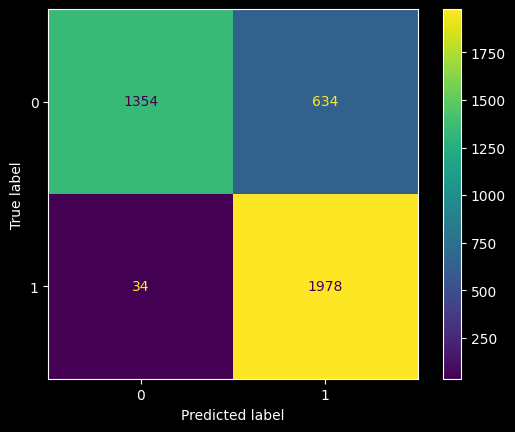

In [198]:
conf_mat_train=ConfusionMatrixDisplay.from_predictions(y_train,y_train_predicted)

In [199]:
# metrics
print(f"""score: {round(accuracy_score(y_train,y_train_predicted),4)}
recall: {round(recall_score(y_train,y_train_predicted),4)}
precision: {round(precision_score(y_train,y_train_predicted),4)}
f1_score: {round(f1_score(y_train,y_train_predicted),4)}""")

score: 0.833
recall: 0.9831
precision: 0.7573
f1_score: 0.8555


In [200]:
# TEST
y_test_predicted=naive_bayes.predict(x_test)

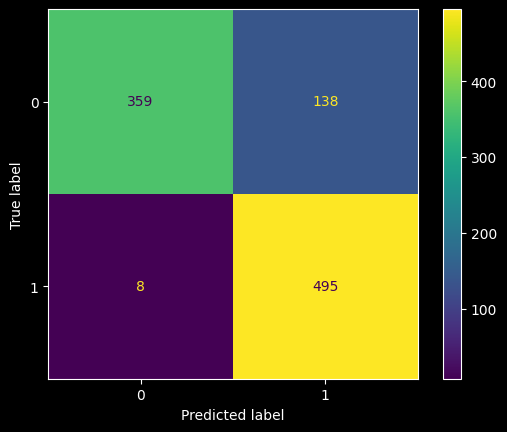

In [201]:
conf_mat_test=ConfusionMatrixDisplay.from_predictions(y_test,y_test_predicted)

In [202]:
# metrics
print(f"""score: {round(accuracy_score(y_test,y_test_predicted),4)}
recall: {round(recall_score(y_test,y_test_predicted),4)}
precision: {round(precision_score(y_test,y_test_predicted),4)}
f1_score: {round(f1_score(y_test,y_test_predicted),4)}""")

score: 0.854
recall: 0.9841
precision: 0.782
f1_score: 0.8715


ACTUAL PREDICTION

In [203]:
input_predict={
 'age':[],
 'gender':[],
 'subscription_type':[],
 'watch_hours':[],
 'last_login_days':[],
 'region':[],
 'device':[],
 'monthly_fee':[],
 'payment_method':[],
 'number_of_profiles':[],
 'avg_watch_time_per_day':[],
 'favorite_genre':[]
 }

In [204]:
input_predict_cols=[x for x in features.columns]
print(*input_predict_cols)

age gender subscription_type watch_hours last_login_days region device monthly_fee payment_method number_of_profiles avg_watch_time_per_day favorite_genre


In [205]:
input_predict_cols=[x for x in features.columns]
for i,col in enumerate(input_predict_cols):
    if col in [x for x in features.select_dtypes(include="number").columns]:
       value=float(input(f"Enter {col} value"))
       input_predict[col].append(value)
    else:
        value=str(input(f"Enter {col} value"))
        input_predict[col].append(value)


In [206]:
new_data=pd.DataFrame(input_predict)

In [207]:
predicted=naive_bayes.predict(new_data)

In [208]:
new_data["churned"]=predicted

In [209]:
new_data

,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre,churned
0,45.0,Male,Standard,2.0,12.0,Africa,Mobile,12.0,Gift Card,5.0,0.59,Action,0
